# CareContinuum AI: Diabetes Readmission Prediction

## 1. Project Objective and Dataset


### Project Objective

CareContinuum AI explores whether hospital readmission among patients with diabetes can be predicted using historical hospital encounter data.

The project will involve understanding the dataset, cleaning and preprocessing the data, building and comparing machine learning models, evaluating their performance, and presenting the findings through an interactive website.

The prediction setting and final model features will be defined after exploring the data and checking which information is available at prediction time.

### Dataset Source

The project uses the Diabetes 130-US Hospitals for Years 1999–2008 dataset from the UCI Machine Learning Repository.

Source: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

Each row represents a hospital encounter. The target variable is `readmitted`, which records whether the patient was readmitted within 30 days, after 30 days, or not readmitted.



## 2. Initial Data Inspection

In this section, we load the dataset and inspect its dimensions, sample records, and target distribution. This provides an initial understanding of the data before performing further analysis and preprocessing.


In [77]:
import pandas as pd 
import numpy as np
import zipfile

zip_path = "diabetes+130-us+hospitals+for+years+1999-2008.zip"

with zipfile.ZipFile(zip_path) as z:
    df = pd.read_csv(z.open("diabetic_data.csv"))
    
print("Shape:", df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nTarget distribution:")
print(df["readmitted"].value_counts())

print("\nTarget percentages:")
print(df["readmitted"].value_counts(normalize=True) * 100)

print("\nQuestion marks by column:")
print((df == "?").sum().sort_values(ascending=False).head(10))

Shape: (101766, 50)

First five rows:
   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   
3                  1                         1                    7   
4                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1  ...   

In [78]:
print("The shape is",df.shape)
print("\n cloumns",df.columns.tolist())
#print("\n dataset info",df.info())
print("\ncounts",df['readmitted'].value_counts())
print("\ncounts",df['readmitted'].value_counts(normalize=True)*100)



The shape is (101766, 50)

 cloumns ['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

counts readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

counts readmitted
NO     53.911916
>30    34.928169
<30    11

In [79]:

print("\nno of empty ",df.isna().sum())


no of empty  encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0


In [80]:

#print("\nno of ? literal ",(df == "?").sum())

#print("\nno of ? literal ",(df == "?").sum().sort_values(ascending=False))
missing_null = df.isna().sum()
missing_question = (df=="?").sum()
missing_percent = ((missing_null + missing_question)/len(df))*100
print("\n missing percentage ", missing_percent.sort_values(ascending=False).head())
print("\n target",df['readmitted'].value_counts())
target_percent = df["readmitted"].value_counts(normalize=True) * 100

print(target_percent.round(2))


 missing percentage  weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
dtype: float64

 target readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


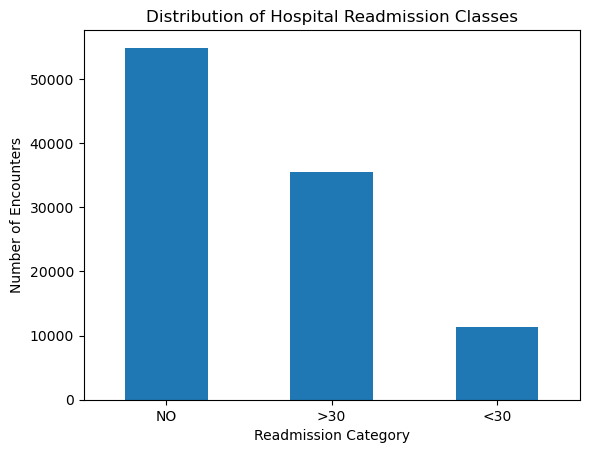

In [81]:
import matplotlib.pyplot as plt

df["readmitted"].value_counts().plot(kind="bar")

plt.title("Distribution of Hospital Readmission Classes")
plt.xlabel("Readmission Category")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=0)
plt.show()


 age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64


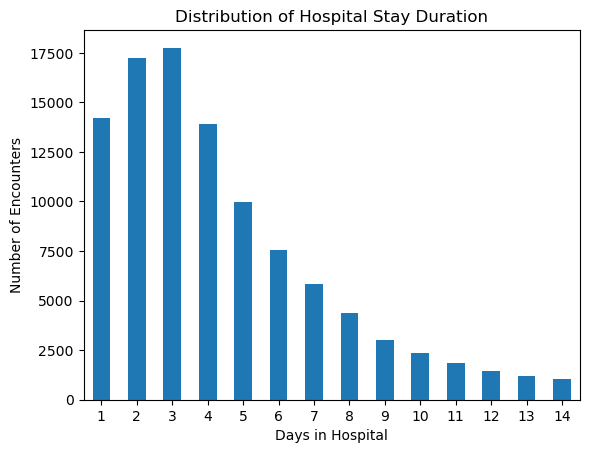

In [82]:
#print(df.dtypes)
print("\n",df['age'].value_counts().sort_index())
df["time_in_hospital"].describe()
df["time_in_hospital"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Hospital Stay Duration")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=0)
plt.show()


In [83]:
in_patient = df['number_inpatient'].value_counts().sort_index().head()
print("\n",in_patient)
out_patient = df['number_outpatient'].value_counts().sort_index().head()
print("\n",out_patient)
emergency = df['number_emergency'].value_counts().sort_index().head()
print("\n",emergency)



 number_inpatient
0    67630
1    19521
2     7566
3     3411
4     1622
Name: count, dtype: int64

 number_outpatient
0    85027
1     8547
2     3594
3     2042
4     1099
Name: count, dtype: int64

 number_emergency
0    90383
1     7677
2     2042
3      725
4      374
Name: count, dtype: int64


In [84]:

pd.crosstab(
    df["number_inpatient"],
    df["readmitted"],
    normalize="index"
).head(10).round(3).mul(100)



readmitted,<30,>30,NO
number_inpatient,,,
0,8.4,30.1,61.5
1,12.9,41.8,45.2
2,17.4,47.5,35.1
3,20.3,49.4,30.3
4,23.6,50.6,25.8
5,31.4,48.6,20.0
6,34.6,49.6,15.8
7,35.4,45.5,19.0
8,44.4,46.4,9.3


In [85]:
pd.crosstab(
    df["number_outpatient"],
    df["readmitted"],
    normalize="index"
).head(10).round(3).mul(100)

readmitted,<30,>30,NO
number_outpatient,,,
0,10.7,33.0,56.3
1,13.9,43.5,42.6
2,13.7,46.4,39.9
3,12.3,45.2,42.6
4,15.1,43.7,41.2
5,11.8,45.6,42.6
6,13.2,50.8,36.0
7,15.5,53.5,31.0
8,5.1,40.8,54.1


In [86]:
pd.crosstab(
    df["number_emergency"],
    df["readmitted"],
    normalize="index"
).head(10).round(3).mul(100)

readmitted,<30,>30,NO
number_emergency,,,
0,10.5,33.4,56.1
1,14.4,44.9,40.7
2,18.3,48.8,32.9
3,20.3,51.6,28.1
4,30.7,50.8,18.4
5,24.5,55.7,19.8
6,23.4,60.6,16.0
7,26.0,64.4,9.6
8,32.0,50.0,18.0


In [87]:
df["diag_1"].value_counts().head(10)

diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

In [88]:

df["diag_2"].value_counts().head(10)


diag_2
276    6752
428    6662
250    6071
427    5036
401    3736
496    3305
599    3288
403    2823
414    2650
411    2566
Name: count, dtype: int64

In [89]:
df["diag_3"].value_counts().head(10)

diag_3
250    11555
401     8289
276     5175
428     4577
427     3955
414     3664
496     2605
403     2357
585     1992
272     1969
Name: count, dtype: int64

In [90]:

for col in ["diag_1", "diag_2", "diag_3"]:
    print(col, ":", (df[col] == '?').sum(), "unknown values")

df["A1Cresult"].value_counts(dropna=False)
df["max_glu_serum"].value_counts(dropna=False)
df["insulin"].value_counts(dropna=False)

for col in ["metformin", "glipizide", "glyburide", "change", "diabetesMed"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


diag_1 : 21 unknown values
diag_2 : 358 unknown values
diag_3 : 1423 unknown values

metformin:
metformin
No        81778
Steady    18346
Up         1067
Down        575
Name: count, dtype: int64

glipizide:
glipizide
No        89080
Steady    11356
Up          770
Down        560
Name: count, dtype: int64

glyburide:
glyburide
No        91116
Steady     9274
Up          812
Down        564
Name: count, dtype: int64

change:
change
No    54755
Ch    47011
Name: count, dtype: int64

diabetesMed:
diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64


In [91]:

df["change"].value_counts(dropna=False)


change
No    54755
Ch    47011
Name: count, dtype: int64

In [92]:
pd.crosstab(
    df["change"],
    df["readmitted"],
    normalize="index"
).mul(100).round(1)

readmitted,<30,>30,NO
change,,,
Ch,11.8,36.7,51.4
No,10.6,33.4,56.0


In [93]:
print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["readmitted"].value_counts(normalize=True).mul(100).round(1))

print("\nColumns containing '?' values:")
print((df == "?").sum().loc[lambda x: x > 0].sort_values(ascending=False))

print("\nColumns with missing NaN values:")
print(df.isna().sum().loc[lambda x: x > 0].sort_values(ascending=False).head(10))

Dataset shape: (101766, 50)

Target distribution:
readmitted
NO     53.9
>30    34.9
<30    11.2
Name: proportion, dtype: float64

Columns containing '?' values:
weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

Columns with missing NaN values:
max_glu_serum    96420
A1Cresult        84748
dtype: int64


In [94]:

# Count the literal "?" markers in the dataset
question_mark_count = (df == "?").sum().sum()

print("Total '?' markers:", question_mark_count)


Total '?' markers: 192849



## 3. Data Quality and Cleaning

This section investigates missing values, duplicate records, and inconsistencies in the dataset. Cleaning decisions are documented with their reasons to make the preprocessing process transparent and reproducible.



### Cleaning Decisions and Rationale

1. **Missing-value markers:** The dataset used `?` to represent missing categorical values. These markers were converted to `NaN` so missing values could be identified consistently.

2. **Duplicate records:** We checked duplicate rows and duplicate encounter IDs. Neither was found, so no records were removed for duplication.

3. **Weight:** The `weight` column was removed because approximately 96.86% of its entries were missing, making it difficult to use reliably.

4. **Medical specialty and diagnoses:** Missing values in `medical_specialty`, `diag_1`, `diag_2`, and `diag_3` were replaced with `Unknown`. This preserves the encounters without inventing values.

5. **Race:** Missing values were replaced with `Unknown` rather than guessing demographic information. Whether this sensitive feature should be included in the model will be considered separately.

6. **Laboratory results:** Missing values in `max_glu_serum` and `A1Cresult` were preserved during exploration. A missing test result must not be assumed to be normal.

7. **Payer code:** `payer_code` is retained in the working dataset for exploration, but excluded from the initial model feature set because it is administrative and has substantial missingness. Its predictive value has not yet been tested.


In [95]:
df_clean = df.replace("?", np.nan)

print("Original '?' markers:", (df == "?").sum().sum())
print("Remaining '?' markers:", (df_clean == "?").sum().sum())
print("Missing values after conversion:", df_clean.isna().sum().sum())


Original '?' markers: 192849
Remaining '?' markers: 0
Missing values after conversion: 374017


In [96]:

missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": df_clean.isna().mean().mul(100).round(2)
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percent", ascending=False)

missing_summary.head(15)


,missing_count,missing_percent
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [97]:

print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate encounter IDs:", df_clean["encounter_id"].duplicated().sum())


Duplicate rows: 0
Duplicate encounter IDs: 0


In [98]:
print("missing values in each columns \n")
print(df_clean.isna().sum().loc[lambda x : x > 0].sort_values(ascending=False))

missing values in each columns 

weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64


In [99]:
for col in ["weight", "max_glu_serum", "A1Cresult"]:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False).head(9))


weight
weight
NaN          98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
Name: count, dtype: int64

max_glu_serum
max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

A1Cresult
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


In [100]:
df_clean = df_clean.drop(columns=["weight"], errors="ignore")
print("initial data shape",df.shape)
print("after dropping weight",df_clean.shape)
print("is weight there ", "weight" in df_clean.columns)

initial data shape (101766, 50)
after dropping weight (101766, 49)
is weight there  False


In [101]:
for col in ["medical_specialty", "payer_code"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False).head(12))


--- medical_specialty ---
medical_specialty
NaN                           49949
InternalMedicine              14635
Emergency/Trauma               7565
Family/GeneralPractice         7440
Cardiology                     5352
Surgery-General                3099
Nephrology                     1613
Orthopedics                    1400
Orthopedics-Reconstructive     1233
Radiologist                    1140
Pulmonology                     871
Psychiatry                      854
Name: count, dtype: int64

--- payer_code ---
payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
Name: count, dtype: int64


In [102]:
df_clean["medical_specialty"] = (
    df_clean["medical_specialty"].fillna("Unknown")
)

print("Missing values:",
      df_clean["medical_specialty"].isna().sum())

print("\nMost common categories:")
print(df_clean["medical_specialty"].value_counts().head(8))

Missing values: 0

Most common categories:
medical_specialty
Unknown                   49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7440
Cardiology                 5352
Surgery-General            3099
Nephrology                 1613
Orthopedics                1400
Name: count, dtype: int64


In [103]:
diagnosis_cols = ["diag_1", "diag_2", "diag_3"]

df_clean[diagnosis_cols] = (
    df_clean[diagnosis_cols].fillna("Unknown")
)

print("Missing diagnosis values:")
print(df_clean[diagnosis_cols].isna().sum())

print("\nDataset shape:", df_clean.shape)

Missing diagnosis values:
diag_1    0
diag_2    0
diag_3    0
dtype: int64

Dataset shape: (101766, 49)


In [104]:

missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (
        df_clean.isna().mean() * 100
    ).round(2)
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

print("Columns that still contain missing values:")
print(missing_summary)

print("\nTotal missing values remaining:", df_clean.isna().sum().sum())


Columns that still contain missing values:
               missing_count  missing_percent
max_glu_serum          96420            94.75
A1Cresult              84748            83.28
payer_code             40256            39.56
race                    2273             2.23

Total missing values remaining: 223697


In [105]:

print("Race categories, including missing values:")
print(df_clean["race"].value_counts(dropna=False))

print("\nMissing race values before cleaning:",
      df_clean["race"].isna().sum())


df_clean["race"] = df_clean["race"].fillna("Unknown")

print("Missing race values after cleaning:",
      df_clean["race"].isna().sum())

print("\nUpdated race categories:")
print(df_clean["race"].value_counts())



Race categories, including missing values:
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

Missing race values before cleaning: 2273
Missing race values after cleaning: 0

Updated race categories:
race
Caucasian          76099
AfricanAmerican    19210
Unknown             2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


In [106]:

for col in ["max_glu_serum", "A1Cresult"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))



--- max_glu_serum ---
max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

--- A1Cresult ---
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


In [107]:
print("Dataset shape:", df_clean.shape)
print("\nMissing values by column:")
print(
    df_clean.isna().sum()
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
)

print("\nTotal missing entries:", df_clean.isna().sum().sum())


Dataset shape: (101766, 49)

Missing values by column:
max_glu_serum    96420
A1Cresult        84748
payer_code       40256
dtype: int64

Total missing entries: 221424


In [108]:

print("Data types of all columns:")
print(df_clean.dtypes.value_counts())

print("\nColumn names:")
print(df_clean.columns.tolist())


Data types of all columns:
object    36
int64     13
Name: count, dtype: int64

Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


In [109]:

print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0].sort_values(ascending=False))


Cleaned dataset shape: (101766, 49)

Remaining missing values:
max_glu_serum    96420
A1Cresult        84748
payer_code       40256
dtype: int64


In [110]:

print("Readmission counts:")
print(df_clean["readmitted"].value_counts())

print("\nReadmission percentages:")
print(
    (df_clean["readmitted"].value_counts(normalize=True) * 100)
    .round(2)
)


Readmission counts:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Readmission percentages:
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64



### Target Distribution and Class Imbalance

The target variable `readmitted` contains three classes: `NO` (53.91%), `>30` (34.93%), and `<30` (11.16%). The classes are imbalanced, with readmission within 30 days being the least frequent outcome. Therefore, accuracy alone may give a misleading impression of model performance. The evaluation will include per-class precision, recall, and F1-score, alongside other suitable metrics.



### Prediction Setting and Leakage Prevention

CareContinuum AI will predict the three-class `readmitted` outcome at hospital discharge: `NO`, `>30`, or `<30`.

Only information available by discharge will be considered as a model input. The target `readmitted` will never be included among the features. The identifiers `encounter_id` and `patient_nbr` will not be used as predictive features. The patient identifier will be retained separately to help prevent encounters from the same patient appearing in both training and test sets.

Preprocessing steps such as missing-value imputation and categorical encoding will be fitted using training data only. The final test set will remain separate until final evaluation.

The dataset contains historical records from 1999–2008, so model performance may not generalize to current hospital practice.


In [111]:
print("Discharge disposition ID counts:")
print(
    df_clean["discharge_disposition_id"]
    .value_counts(dropna=False)
    .sort_index()
)

Discharge disposition ID counts:
discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64


In [112]:
with zipfile.ZipFile(zip_path) as z:
    id_mapping = pd.read_csv(z.open("IDS_mapping.csv"))

print("Mapping columns:")
print(id_mapping.columns.tolist())

print("\nFirst 10 rows:")
print(id_mapping.head(10))

Mapping columns:
['admission_type_id', 'description']

First 10 rows:
          admission_type_id    description
0                         1      Emergency
1                         2         Urgent
2                         3       Elective
3                         4        Newborn
4                         5  Not Available
5                         6            NaN
6                         7  Trauma Center
7                         8     Not Mapped
8                       NaN            NaN
9  discharge_disposition_id    description


In [113]:
with zipfile.ZipFile(zip_path) as z:
    mapping_text = z.read("IDS_mapping.csv").decode("utf-8")

start = mapping_text.find("discharge_disposition_id")
end = mapping_text.find("admission_source_id")

print(mapping_text[start:end])

discharge_disposition_id,description
1,Discharged to home
2,Discharged/transferred to another short term hospital
3,Discharged/transferred to SNF
4,Discharged/transferred to ICF
5,Discharged/transferred to another type of inpatient care institution
6,Discharged/transferred to home with home health service
7,Left AMA
8,Discharged/transferred to home under care of Home IV provider
9,Admitted as an inpatient to this hospital
10,Neonate discharged to another hospital for neonatal aftercare
11,Expired
12,Still patient or expected to return for outpatient services
13,Hospice / home
14,Hospice / medical facility
15,Discharged/transferred within this institution to Medicare approved swing bed
16,Discharged/transferred/referred another institution for outpatient services
17,Discharged/transferred/referred to this institution for outpatient services
18,NULL
19,"Expired at home. Medicaid only, hospice."
20,"Expired in a medical facility. Medicaid only, hospice."
21,"Expired, place unknown. Medica


### Handling Discharge Outcomes

The discharge disposition codes were inspected using the dataset's `IDS_mapping.csv` file. Encounters with discharge codes indicating that the patient expired or was discharged to hospice will be excluded from the initial modeling cohort because readmission is not a meaningful outcome for these cases.

This decision narrows the population to encounters for which readmission can reasonably be studied. The excluded records will be counted and documented before modeling. The discharge disposition identifier will not be used as an initial predictive feature.


In [114]:
exclude_disposition_ids = [11, 13, 14, 19, 20, 21]

excluded_mask = df_clean["discharge_disposition_id"].isin(
    exclude_disposition_ids
)

print("Encounters flagged for exclusion:", excluded_mask.sum())
print("\nCounts by discharge disposition:")
print(
    df_clean.loc[excluded_mask, "discharge_disposition_id"]
    .value_counts()
    .sort_index()
)

Encounters flagged for exclusion: 2423

Counts by discharge disposition:
discharge_disposition_id
11    1642
13     399
14     372
19       8
20       2
Name: count, dtype: int64



### Discharge Outcome Review

The discharge disposition codes were inspected using the dataset's `IDS_mapping.csv` file. A total of 2,423 encounters were flagged: 1,642 with disposition code 11 (expired), 399 with code 13 (hospice/home), 372 with code 14 (hospice/medical facility), 8 with code 19 (expired at home), and 2 with code 20 (expired in a medical facility). No encounters had code 21 in the current dataset.

These records are flagged for exclusion from the initial modeling cohort because death makes subsequent readmission undefined, while hospice discharge represents a distinct care situation. This is a deliberate restriction of the population being studied. The original cleaned dataset will be preserved, and the number of removed encounters will be recorded.


In [115]:
# Create a separate dataset for modeling
df_model = df_clean.loc[~excluded_mask].copy()

print("Original cleaned dataset shape:", df_clean.shape)
print("Modeling dataset shape:", df_model.shape)
print("Encounters excluded:", len(df_clean) - len(df_model))

Original cleaned dataset shape: (101766, 49)
Modeling dataset shape: (99343, 49)
Encounters excluded: 2423


In [116]:
print("Readmission counts in modeling dataset:")
print(df_model["readmitted"].value_counts())

print("\nReadmission percentages in modeling dataset:")
print(
    (df_model["readmitted"].value_counts(normalize=True) * 100)
    .round(2)
)

Readmission counts in modeling dataset:
readmitted
NO     52527
>30    35502
<30    11314
Name: count, dtype: int64

Readmission percentages in modeling dataset:
readmitted
NO     52.87
>30    35.74
<30    11.39
Name: proportion, dtype: float64


In [117]:
missing_summary_model = pd.DataFrame({
    "missing_count": df_model.isna().sum(),
    "missing_percent": (
        df_model.isna().mean() * 100
    ).round(2)
})

missing_summary_model = (
    missing_summary_model[
        missing_summary_model["missing_count"] > 0
    ]
    .sort_values("missing_percent", ascending=False)
)

print(missing_summary_model)

               missing_count  missing_percent
max_glu_serum          94191            94.81
A1Cresult              82509            83.05
payer_code             39398            39.66


In [118]:
test_columns = ["max_glu_serum", "A1Cresult"]

for col in test_columns:
    print(f"\n{col}")
    print(df_model[col].value_counts(dropna=False))


max_glu_serum
max_glu_serum
NaN     94191
Norm     2545
>200     1419
>300     1188
Name: count, dtype: int64

A1Cresult
A1Cresult
NaN     82509
>8       8137
Norm     4922
>7       3775
Name: count, dtype: int64



### Missing-Value Decisions

After defining the initial modeling cohort, three columns still contain missing values: `max_glu_serum` (94.81%), `A1Cresult` (83.05%), and `payer_code` (39.66%).

The missing values in `max_glu_serum` and `A1Cresult` indicate that results were not recorded in the dataset; they will not be treated as normal test results. Both columns will be retained for now so their potential predictive value can be assessed. Any imputation will be fitted using training data only.

`payer_code` will remain in the working dataset for traceability but will be excluded from the initial model feature set because it is an administrative variable with substantial missingness and uncertain incremental value.


In [119]:
print("Dataset shape:", df_model.shape)

print("\nColumn names and data types:")
print(df_model.dtypes.to_string())

Dataset shape: (99343, 49)

Column names and data types:
encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              objec

In [120]:
# Check how many distinct values each column contains
unique_counts = df_model.nunique(dropna=False).sort_values()

print("Columns with 1 or fewer distinct values:")
print(unique_counts[unique_counts <= 1])

print("\nNumber of distinct values per column:")
print(unique_counts.to_string())

Columns with 1 or fewer distinct values:
citoglipton    1
examide        1
dtype: int64

Number of distinct values per column:
citoglipton                     1
examide                         1
tolbutamide                     2
acetohexamide                   2
change                          2
troglitazone                    2
metformin-pioglitazone          2
metformin-rosiglitazone         2
glimepiride-pioglitazone        2
glipizide-metformin             2
diabetesMed                     2
gender                          3
tolazamide                      3
readmitted                      3
metformin                       4
max_glu_serum                   4
miglitol                        4
insulin                         4
rosiglitazone                   4
pioglitazone                    4
acarbose                        4
glyburide                       4
repaglinide                     4
nateglinide                     4
glimepiride                     4
A1Cresult              

In [121]:
constant_columns = ["citoglipton", "examide"]
df_model = df_model.drop(columns=constant_columns,errors="ignore")

print("Removed columns:", constant_columns)
print("Updated modeling dataset shape:", df_model.shape)

Removed columns: ['citoglipton', 'examide']
Updated modeling dataset shape: (99343, 47)



### Initial Feature-Selection Plan

The columns `citoglipton` and `examide` were removed from the modeling dataset because each contains only one distinct value and therefore provides no variation for prediction.

The following columns will not be used as initial predictive features:

- `encounter_id`: unique encounter identifier.
- `patient_nbr`: patient identifier, retained separately for patient-aware data splitting.
- `readmitted`: target variable to be predicted, never an input feature.
- `payer_code`: administrative variable with substantial missingness and uncertain incremental predictive value.
- `discharge_disposition_id`: excluded from the initial feature set because discharge outcomes include hospice-related categories and require careful interpretation.

All other remaining columns are candidates for further review. Feature eligibility will be finalized based on availability at discharge, missingness, and the risk of information leakage.


In [122]:
# Keep the patient IDs separately for a patient-aware data split
patient_ids = df_model["patient_nbr"].copy()

# Columns that must not be used as predictive features
columns_to_exclude = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "payer_code",
    "discharge_disposition_id"
]

# Create features (X) and target (y)
X = df_model.drop(columns=columns_to_exclude)
y = df_model["readmitted"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Feature matrix shape: (99343, 42)
Target shape: (99343,)

Target classes:
readmitted
NO     52527
>30    35502
<30    11314
Name: count, dtype: int64



### Train/Test Split and Cross-Validation Strategy

The dataset contains multiple encounters for some patients. To reduce patient-level data leakage, encounters belonging to the same `patient_nbr` will be kept together.

First, `GroupShuffleSplit` will reserve approximately 20% of patients for a held-out test set. The remaining patients will form the training set.

Second, `StratifiedGroupKFold` will be used for cross-validation within the training set to compare candidate models and select model settings. It attempts to preserve the proportions of the three readmission classes while keeping patients grouped.

A fixed random seed will be used for reproducibility. Class distributions and patient overlap will be checked after splitting. The test set will remain untouched during model selection and preprocessing decisions.


In [123]:
from sklearn.model_selection import GroupShuffleSplit

# Stage 1: Reserve approximately 20% of patients for final testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=patient_ids)
)

# Create training and test sets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = patient_ids.iloc[train_idx].copy()
groups_test = patient_ids.iloc[test_idx].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (79541, 42)
Testing features: (19802, 42)
Training target: (79541,)
Testing target: (19802,)


In [124]:
# Check whether any patient appears in both sets
overlap = set(groups_train.unique()) & set(groups_test.unique())

print("Unique patients in training:", groups_train.nunique())
print("Unique patients in testing:", groups_test.nunique())
print("Patients appearing in both sets:", len(overlap))

Unique patients in training: 55992
Unique patients in testing: 13998
Patients appearing in both sets: 0


In [125]:
print("Training class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting class percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training class percentages:
readmitted
NO     52.84
>30    35.72
<30    11.44
Name: proportion, dtype: float64

Testing class percentages:
readmitted
NO     53.00
>30    35.80
<30    11.19
Name: proportion, dtype: float64


In [126]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation splitter created.")
print("Number of folds:", cv.get_n_splits())

Cross-validation splitter created.
Number of folds: 5


In [127]:
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups_train),
    start=1
):
    print("Fold:", fold)
    print("Training rows:", len(train_idx))
    print("Validation rows:", len(val_idx))

    if fold == 1:
        break
    
    
# Get the patient IDs for the first fold
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups_train),
    start=1
):
    train_patients = groups_train.iloc[train_idx]
    val_patients = groups_train.iloc[val_idx]

    overlap = set(train_patients) & set(val_patients)

    print("Patients in both training and validation:", len(overlap))

    break

fold_number = 0

for train_idx, val_idx in cv.split(
    X_train, y_train, groups=groups_train
):
    fold_number += 1

    train_patients = set(groups_train.iloc[train_idx])
    val_patients = set(groups_train.iloc[val_idx])

    overlap = train_patients & val_patients

    print(
        f"Fold {fold_number}: "
        f"patient overlap = {len(overlap)}"
    )

Fold: 1
Training rows: 63380
Validation rows: 16161
Patients in both training and validation: 0
Fold 1: patient overlap = 0
Fold 2: patient overlap = 0
Fold 3: patient overlap = 0
Fold 4: patient overlap = 0
Fold 5: patient overlap = 0


In [128]:
cv_splits = list(
    cv.split(X_train, y_train, groups=groups_train)
)

print("Number of folds generated:", len(cv_splits))

Number of folds generated: 5


In [129]:
print("Number of features:", X.shape[1])

print("\nData types of our features:")
print(X.dtypes.value_counts())

Number of features: 42

Data types of our features:
object    32
int64     10
Name: count, dtype: int64


In [130]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))

print("\nNumerical column names:")
print(numerical_cols)

Categorical features: 32
Numerical features: 10

Numerical column names:
['admission_type_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [131]:
for col in numerical_cols:
    print(
        col,
        "| unique values:", X[col].nunique(),
        "| examples:", X[col].dropna().unique()[:10]
    )

admission_type_id | unique values: 8 | examples: [6 1 2 3 4 5 8 7]
admission_source_id | unique values: 17 | examples: [ 1  7  2  4  5 20  6  3 17  8]
time_in_hospital | unique values: 14 | examples: [ 1  3  2  4  5 13 12  9  7 10]
num_lab_procedures | unique values: 118 | examples: [41 59 11 44 51 31 70 73 68 33]
num_procedures | unique values: 7 | examples: [0 5 1 6 2 3 4]
num_medications | unique values: 75 | examples: [ 1 18 13 16  8 21 12 28 17 11]
number_outpatient | unique values: 39 | examples: [ 0  2  1  5  7  9  3  8  4 12]
number_emergency | unique values: 33 | examples: [0 1 2 4 3 9 5 7 6 8]
number_inpatient | unique values: 21 | examples: [0 1 2 3 6 5 4 7 9 8]
number_diagnoses | unique values: 16 | examples: [ 1  9  6  7  5  8  3  4  2 16]


In [132]:
categorical_cols = categorical_cols + [
    "admission_type_id",
    "admission_source_id"
]

numerical_cols = [
    col for col in numerical_cols
    if col not in [
        "admission_type_id",
        "admission_source_id"
    ]
]

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))

print("\nNumerical columns:")
print(numerical_cols)

Categorical features: 34
Numerical features: 8

Numerical columns:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [133]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Preprocessing tools imported successfully.")

Preprocessing tools imported successfully.


### Feature Types and Preprocessing Plan

The initial feature matrix contains 42 candidate features: 34 categorical features and 8 numerical features.

The `admission_type_id` and `admission_source_id` columns are stored as integers but represent category codes, so they will initially be treated as categorical features. The remaining eight numerical features represent counts or hospital-stay duration.

The preprocessing plan is:

- **Numerical features:** impute missing values using the median and standardize the values for models such as Logistic Regression.
- **Categorical features:** impute missing values using the most frequent category and apply one-hot encoding.
- **Leakage prevention:** fit all preprocessing steps using the training portion of each cross-validation fold, then apply the fitted transformations to its validation portion.

The preprocessing choices will be implemented through scikit-learn pipelines so that the transformations are consistently applied during model comparison and final evaluation.

In [134]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


### Categorical Feature Preprocessing

Categorical features contain labels or codes rather than continuous numerical measurements. Examples include `gender`, `race`, medication status, and admission type.

The categorical preprocessing pipeline will:

1. Replace missing values with the most frequent category learned from the training data.
2. Apply one-hot encoding to represent categories as numerical indicator columns.

One-hot encoding avoids incorrectly treating category labels as ordered quantities. The encoder will also be configured to handle categories that appear in validation or test data but were not observed during fitting.

The pipeline will be fitted only on the relevant training data to prevent information leakage.

In [135]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


### Combining Numerical and Categorical Preprocessing

The numerical and categorical pipelines will be combined using scikit-learn's `ColumnTransformer`.

The numerical pipeline will process the eight numerical columns, while the categorical pipeline will process the 34 categorical columns. This ensures that each feature receives the appropriate transformations.

The combined preprocessor will later be placed inside the model pipeline. During cross-validation, each fold's training data will be used to fit the preprocessing steps, and its validation data will only be transformed. This prevents preprocessing information from leaking across folds.

In [136]:
preprocessor = ColumnTransformer(transformers=
                [("numeric" , numeric_pipeline,numerical_cols),
                ("categorical",categorical_pipeline,categorical_cols)])

print("Combined processor created")

Combined processor created


### First Candidate Model: Logistic Regression

Logistic Regression will be our first trainable classification model. It provides a useful baseline for comparing more complex models.

The model will receive the processed features from the combined preprocessor and learn to predict the three readmission classes: `NO`, `>30`, and `<30`.

The preprocessor and classifier will be placed inside a single scikit-learn pipeline. This allows preprocessing to be fitted on the training portion of each cross-validation fold and applied to its validation portion without fitting on validation data.

Model performance will be evaluated using class-aware metrics rather than accuracy alone.

In [137]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


### Baseline Model: Majority-Class Prediction

Before evaluating Logistic Regression, we will establish a simple baseline using `DummyClassifier`. This model predicts the most frequent readmission class in the training data for every encounter.

The baseline does not learn relationships between patient features and readmission. It provides a reference point for evaluating whether a trainable model offers useful predictive improvement.

We will evaluate all three classes — `NO`, `>30`, and `<30` — rather than relying on accuracy alone. Cross-validation will use the patient-grouped folds created earlier.

In [138]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

print("Majority-class baseline created.")

Majority-class baseline created.


### Evaluating the Baseline with Cross-Validation

We will evaluate the majority-class baseline using the five patient-grouped cross-validation folds created earlier. In each fold, the model learns the most frequent class from that fold's training data and predicts that class for its validation data.

We will record accuracy and macro F1-score for each fold. Macro F1 gives equal importance to `NO`, `>30`, and `<30`, making it useful when the target classes are imbalanced.

The validation folds will not be used to fit the model.

In [139]:
from sklearn.model_selection import cross_validate

baseline_scores = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1
)

print("Baseline cross-validation results")
print("Mean accuracy:", baseline_scores["test_accuracy"].mean())
print("Mean macro F1:", baseline_scores["test_macro_f1"].mean())

Baseline cross-validation results
Mean accuracy: 0.5284305609554087
Mean macro F1: 0.23048662764622074


### Baseline Results and Interpretation

The majority-class baseline achieved a mean cross-validation accuracy of approximately 52.84% and a mean macro F1-score of approximately 0.231.

The baseline predicts only the most frequent class and does not learn relationships between patient features and readmission. Consequently, it cannot identify encounters belonging to the other two classes.

These results establish a reference point for evaluating Logistic Regression. We will examine whether a trainable model improves performance across all three classes, rather than judging improvement by accuracy alone.

In [140]:
logistic_scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1
)

print("Logistic Regression cross-validation results")
print(
    "Mean accuracy:",
    logistic_scores["test_accuracy"].mean()
)
print(
    "Mean macro F1:",
    logistic_scores["test_macro_f1"].mean()
)

Logistic Regression cross-validation results
Mean accuracy: 0.5734913054830513
Mean macro F1: 0.391409098197742


### Class-Wise Evaluation of Logistic Regression

Overall accuracy and macro F1 do not show how well the model predicts each readmission class individually.

We will generate out-of-fold predictions using the existing patient-grouped cross-validation splits. Each encounter will be predicted by a model trained without that encounter's validation fold.

We will then calculate precision, recall, and F1-score for `NO`, `>30`, and `<30`. These results will help identify which classes the model handles well and which it struggles to recognize.

The final test set remains untouched during this cross-validation analysis.

In [141]:
from sklearn.model_selection import cross_val_predict

logistic_oof_predictions = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv_splits,
    n_jobs=-1
)

print("Out-of-fold predictions generated.")
print(
    "Number of predictions:",
    len(logistic_oof_predictions)
)

Out-of-fold predictions generated.
Number of predictions: 79541


### Classification Report: Logistic Regression

We generated out-of-fold predictions for all training encounters using the five patient-grouped cross-validation folds.

We will now compare these predictions with the actual target labels using a classification report. The report includes precision, recall, F1-score, and the number of actual encounters in each class.

This analysis will show whether Logistic Regression performs consistently across `NO`, `>30`, and `<30`, or whether it struggles with particular classes.

In [142]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_train,
        logistic_oof_predictions,
        labels=["NO", ">30", "<30"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

          NO       0.60      0.82      0.70     42031
         >30       0.50      0.38      0.43     28412
         <30       0.34      0.02      0.05      9098

    accuracy                           0.57     79541
   macro avg       0.48      0.41      0.39     79541
weighted avg       0.54      0.57      0.53     79541



### Confusion Matrix: Logistic Regression

A confusion matrix compares the actual readmission classes with the classes predicted by Logistic Regression.

Rows represent actual classes, and columns represent predicted classes. Values on the diagonal are correct predictions, while off-diagonal values represent misclassifications.

We will use the out-of-fold predictions from patient-grouped cross-validation to investigate which classes the model identifies correctly and which it confuses with other classes.

In [143]:
from sklearn.metrics import confusion_matrix
import pandas as pd

class_order = ["NO", ">30", "<30"]

cm = confusion_matrix(
    y_train,
    logistic_oof_predictions,
    labels=class_order
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {c}" for c in class_order],
    columns=[f"Predicted {c}" for c in class_order]
)

cm_df

,Predicted NO,Predicted >30,Predicted <30
Actual NO,34581,7300,150
Actual >30,17316,10814,282
Actual <30,5310,3565,223


### Confusion Matrix Findings

The out-of-fold confusion matrix shows substantial differences in performance across the three readmission classes.

Logistic Regression identifies the `NO` class relatively well, with a recall of approximately 82.3%. Recall for `>30` is approximately 38.1%, while recall for `<30` is only approximately 2.45%.

Most actual `<30` encounters are misclassified as either `NO` or `>30`. This indicates that overall accuracy alone does not adequately describe the model's performance.

The class imbalance may contribute to this result. We will investigate class-aware training and evaluation methods, while checking whether any improvement in minority-class recall comes at the cost of precision or performance on other classes.

### Experiment: Class-Weighted Logistic Regression

The initial Logistic Regression model showed poor recall for the `<30` readmission class. We will test whether class weighting improves performance across the three classes.

Setting `class_weight="balanced"` adjusts class weights inversely according to their frequencies in the training data. We will keep the same preprocessing pipeline and patient-grouped cross-validation folds so that the results can be compared fairly with the original Logistic Regression model.

This is an experiment, not a guaranteed improvement. We will compare accuracy, macro F1, and class-wise precision and recall.

In [144]:
weighted_logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Class-weighted Logistic Regression pipeline created.")

Class-weighted Logistic Regression pipeline created.


### Evaluating Class-Weighted Logistic Regression

We will evaluate the class-weighted model using the same five patient-grouped cross-validation folds as the original Logistic Regression model.

We will measure accuracy and macro F1. Accuracy measures the overall proportion of correct predictions, while macro F1 gives equal importance to the F1-score of each of the three classes.

Comparing these metrics will help us determine whether class weighting improves performance across the readmission classes.

In [145]:
weighted_scores = cross_validate(
    weighted_logistic_model,
    X_train,
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=-1
)

print("Class-weighted Logistic Regression results")
print("Mean accuracy:", weighted_scores["test_accuracy"].mean())
print("Mean macro F1:", weighted_scores["test_macro_f1"].mean())

Class-weighted Logistic Regression results
Mean accuracy: 0.481724472776526
Mean macro F1: 0.42619274548964875


### Class-Wise Evaluation of Class-Weighted Logistic Regression

The class-weighted model achieved a higher mean macro F1 but a lower mean accuracy than the original Logistic Regression model.

We will generate out-of-fold predictions using the same patient-grouped cross-validation folds and examine the classification report for each readmission class. This will help us determine whether class weighting improved recognition of the less frequent classes and understand the associated trade-offs.

In [146]:
weighted_oof_predictions = cross_val_predict(
    weighted_logistic_model,
    X_train,
    y_train,
    cv=cv_splits,
    n_jobs=-1
)

print("Weighted-model predictions generated.")
print("Number of predictions:", len(weighted_oof_predictions))

Weighted-model predictions generated.
Number of predictions: 79541


### Interpreting Class-Wise Performance

We will calculate precision, recall, and F1-score for each readmission class using the class-weighted model's out-of-fold predictions.

This evaluation is important because the three classes have different frequencies. A model can improve its overall macro F1 while still performing poorly on an individual class.

In [147]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_train,
        weighted_oof_predictions,
        labels=["NO", ">30", "<30"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

          NO       0.66      0.57      0.61     42031
         >30       0.46      0.39      0.42     28412
         <30       0.18      0.40      0.25      9098

    accuracy                           0.48     79541
   macro avg       0.43      0.45      0.43     79541
weighted avg       0.53      0.48      0.50     79541



### Interpretation: Class-Weighted Logistic Regression

The class-weighted Logistic Regression model achieved a mean cross-validation accuracy of approximately 0.482 and a mean macro F1-score of approximately 0.426.

Compared with the original Logistic Regression model, macro F1 increased from approximately 0.391 to 0.426, while accuracy decreased from approximately 0.573 to 0.482.

For the `<30` class, recall increased from 0.02 to 0.40 and F1-score increased from 0.05 to 0.25. However, precision decreased from 0.34 to 0.18, indicating that many predictions for this class were incorrect.

These results illustrate the trade-off between overall accuracy and recognition of less frequent classes. Class weighting improves minority-class recall in this experiment, but further evaluation is required before selecting the final model.

### Comparing Candidate Models

We evaluated two Logistic Regression configurations using the same five patient-grouped cross-validation folds.

- **Original Logistic Regression:** The initial trainable model, without class weighting.
- **Class-Weighted Logistic Regression:** A modified model that gives greater importance to less frequent classes during training.

We compare mean accuracy and mean macro F1 to understand the trade-off between overall correctness and balanced performance across the three readmission classes. These cross-validation results are used for model comparison; the held-out test set remains reserved for final evaluation.

In [148]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Class-Weighted Logistic Regression"
    ],
    "Mean Accuracy": [
        logistic_scores["test_accuracy"].mean(),
        weighted_scores["test_accuracy"].mean()
    ],
    "Mean Macro F1": [
        logistic_scores["test_macro_f1"].mean(),
        weighted_scores["test_macro_f1"].mean()
    ]
})

model_comparison.round(4)

,Model,Mean Accuracy,Mean Macro F1
0,Original Logistic Regression,0.5735,0.3914
1,Class-Weighted Logistic Regression,0.4817,0.4262


### Next Candidate: Random Forest

Random Forest is an ensemble learning method that combines predictions from multiple decision trees. It can model nonlinear relationships and interactions between features.

We will compare a class-weighted Random Forest with our Logistic Regression candidates using the same five patient-grouped cross-validation folds. We will evaluate mean accuracy and macro F1, followed by class-wise metrics.

This experiment will help us determine whether a more flexible model improves predictive performance. All model selection will use training data; the held-out test set will remain untouched until final evaluation.

In [160]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

print("Class-weighted Random Forest pipeline created.")

Class-weighted Random Forest pipeline created.


### Evaluating Class-Weighted Random Forest

We will evaluate the class-weighted Random Forest using the same five patient-grouped cross-validation folds used for our Logistic Regression experiments.

We will calculate mean accuracy and mean macro F1. Using the same folds makes the comparison more consistent and helps us assess whether Random Forest improves the balance of performance across the three readmission classes.

The held-out test set will remain unused during model selection.

In [ ]:
rf_scores = cross_validate(rf_model,
                           X_train,
                           y_train,cv=cv_splits,scoring={    "accuracy": "accuracy",    "macro_f1": "f1_macro"},
    n_jobs=-1
)

print("Class-weighted Random Forest results")
print("Mean accuracy:", rf_scores["test_accuracy"].mean())
print("Mean macro F1:", rf_scores["test_macro_f1"].mean())

KeyboardInterrupt: 

### Computational Cost of Random Forest

The class-weighted Random Forest experiment was interrupted because five-fold cross-validation was taking too long on the large, high-dimensional dataset.

Rather than repeatedly running an expensive experiment, we will first compare the models using the results already obtained. If Random Forest remains a promising candidate, we can test a smaller configuration or a carefully selected subset of the training data.

This is a computational limitation, not evidence that Random Forest performs poorly. We will record the limitation honestly and avoid drawing conclusions without completed evaluation results.

In [163]:
print("Original Logistic Regression:")
print("Accuracy:", round(logistic_scores["test_accuracy"].mean(), 4))
print("Macro F1:", round(logistic_scores["test_macro_f1"].mean(), 4))

print("\nClass-weighted Logistic Regression:")
print("Accuracy:", round(weighted_scores["test_accuracy"].mean(), 4))
print("Macro F1:", round(weighted_scores["test_macro_f1"].mean(), 4))

print("\nRandom Forest results available:", "rf_scores" in globals())

Original Logistic Regression:
Accuracy: 0.5735
Macro F1: 0.3914

Class-weighted Logistic Regression:
Accuracy: 0.4817
Macro F1: 0.4262

Random Forest results available: True


### Preliminary Random Forest Experiment

The full Random Forest cross-validation experiment was interrupted because of its high computational cost.

We will conduct a smaller preliminary experiment using a subset of the training data and a reduced number of trees. This experiment will help us assess whether Random Forest is worth further investigation.

Because it uses less data and a smaller model, its results will not be directly comparable to the five-fold cross-validation results of Logistic Regression. We will treat it as exploratory evidence only.

In [164]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

small_rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
])

print("Small Random Forest pipeline created.")

Small Random Forest pipeline created.


### Training a Preliminary Random Forest

We will train the smaller Random Forest on a subset of the training data. This allows us to test the training workflow without repeating the expensive five-fold experiment.

The subset will be selected deterministically for reproducibility. The model will be evaluated on a separate subset of training encounters that it did not use during fitting.

This is an exploratory experiment. Its results are not directly comparable to the full-data cross-validation results of Logistic Regression.

In [165]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

X_small, _, y_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.10,
    random_state=42,
    stratify=y_train
)

X_rf_train, X_rf_valid, y_rf_train, y_rf_valid = train_test_split(
    X_small,
    y_small,
    test_size=0.20,
    random_state=42,
    stratify=y_small
)

print("Random Forest training rows:", len(X_rf_train))
print("Random Forest validation rows:", len(X_rf_valid))

Random Forest training rows: 6363
Random Forest validation rows: 1591


### Preliminary Random Forest Experiment

A Random Forest classifier is being tested on a smaller subset of the training data because the full five-fold experiment was interrupted due to its computational cost.

This experiment is exploratory. Its results will help us assess whether Random Forest is practical to train in the available environment. Because it uses a smaller subset and a single validation split, its results will not be directly comparable to the five-fold cross-validation results of Logistic Regression.

In [166]:
import time

start_time = time.time()

small_rf_model.fit(X_rf_train, y_rf_train)

training_seconds = time.time() - start_time

print("Random Forest training completed.")
print("Training time (seconds):", round(training_seconds, 2))

Random Forest training completed.
Training time (seconds): 2.63


### Evaluating the Preliminary Random Forest

After training, we generate predictions for the validation subset, which was not used to fit the model. We will compare these predictions with the actual readmission labels using accuracy, macro F1-score, and a class-wise classification report.

This is an exploratory evaluation on a smaller, row-stratified subset. It is not a final estimate of model performance, and the split does not guarantee that encounters from the same patient are kept together.

In [167]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_valid_predictions = small_rf_model.predict(X_rf_valid)

print("Validation accuracy:", round(
    accuracy_score(y_rf_valid, rf_valid_predictions), 4
))

print("Validation macro F1:", round(
    f1_score(y_rf_valid, rf_valid_predictions, average="macro"), 4
))

print("\nClass-wise classification report:")

print(classification_report(
    y_rf_valid,
    rf_valid_predictions,
    labels=["NO", ">30", "<30"],
    zero_division=0
))

Validation accuracy: 0.5443
Validation macro F1: 0.3591

Class-wise classification report:
              precision    recall  f1-score   support

          NO       0.58      0.80      0.67       841
         >30       0.45      0.33      0.38       568
         <30       0.40      0.01      0.02       182

    accuracy                           0.54      1591
   macro avg       0.48      0.38      0.36      1591
weighted avg       0.51      0.54      0.49      1591



### Interpretation of Preliminary Random Forest Results

The preliminary Random Forest achieved 54.43% validation accuracy and a macro F1-score of 0.3591 on the small validation subset.

Performance varied substantially across the readmission classes. Recall was 0.80 for `NO`, 0.33 for `>30`, and only 0.01 for `<30`. The model therefore performed poorly at identifying encounters associated with readmission within 30 days.

These results show that accuracy alone does not adequately describe performance across the three classes. However, this experiment uses a smaller, encounter-level split and is exploratory; it does not establish the model's final generalization performance.

The next step is to examine a confusion matrix to understand which classes are being confused with one another.

### Confusion Matrix: Preliminary Random Forest

A confusion matrix compares actual classes with predicted classes. Each row represents the actual class, and each column represents the predicted class.

The diagonal entries are correct predictions. The off-diagonal entries show misclassifications. We will use this matrix to investigate whether the model is incorrectly assigning early readmissions (`<30`) to other classes.

In [168]:
from sklearn.metrics import confusion_matrix
import pandas as pd

class_order = ["NO", ">30", "<30"]

rf_cm = confusion_matrix(
    y_rf_valid,
    rf_valid_predictions,
    labels=class_order
)

rf_cm_df = pd.DataFrame(
    rf_cm,
    index=[f"Actual {c}" for c in class_order],
    columns=[f"Predicted {c}" for c in class_order]
)

rf_cm_df

,Predicted NO,Predicted >30,Predicted <30
Actual NO,674,165,2
Actual >30,377,190,1
Actual <30,110,70,2


### Interpretation and Computational Limitation of the Preliminary Random Forest

The preliminary Random Forest was trained on a smaller subset of the training data and evaluated on a single validation split. It achieved approximately 54.43% accuracy and a macro F1-score of 0.3591.

The class-wise results show that the model performed unevenly. Recall was approximately 0.80 for `NO`, 0.33 for `>30`, and 0.01 for `<30`. Therefore, the model identified the `NO` class much more effectively than either readmission class, especially `<30`.

The full five-fold Random Forest experiment was interrupted because of its computational cost. The subset experiment is exploratory and is not directly comparable to the five-fold cross-validation results of Logistic Regression. These results do not establish that Random Forest is inherently worse; a fair comparison would require comparable evaluation procedures.

The model is not suitable for clinical decision-making. Further evaluation should prioritize class-wise recall, macro F1-score, confusion matrices, and performance on the held-out test set.


### Comparing Candidate Models: Current Evidence

The original Logistic Regression achieved a mean accuracy of 0.5735 and a mean macro F1-score of 0.3914 under five-fold cross-validation.

Class-weighted Logistic Regression achieved a mean accuracy of 0.4817 and a mean macro F1-score of 0.4262 under the same evaluation procedure. This indicates a trade-off: class weighting improved macro F1-score but reduced overall accuracy.

The preliminary Random Forest achieved 0.5443 accuracy and 0.3591 macro F1-score on a single validation split using a smaller subset. Because its evaluation setup differs from that of Logistic Regression, these numbers should not be treated as a direct model ranking.

The next stage will prioritize reliable class-wise evaluation and final testing on the held-out test set. The `<30` readmission class requires particular attention because the preliminary Random Forest showed extremely low recall for it.


In [169]:
print("Original Logistic Regression saved:", "logistic_scores" in globals())
print("Class-weighted Logistic Regression saved:", "weighted_scores" in globals())
print("Random Forest scores saved:", "rf_scores" in globals())
print("Random Forest predictions saved:", "rf_valid_predictions" in globals())
print("Held-out test features saved:", "X_test" in globals())
print("Held-out test labels saved:", "y_test" in globals())

Original Logistic Regression saved: True
Class-weighted Logistic Regression saved: True
Random Forest scores saved: True
Random Forest predictions saved: True
Held-out test features saved: True
Held-out test labels saved: True


### Interpreting the Current Model Experiments

The original Logistic Regression achieved a mean accuracy of 0.5735 and a mean macro F1-score of 0.3914. Class-weighted Logistic Regression achieved a lower mean accuracy of 0.4817 but a higher mean macro F1-score of 0.4262.

This trade-off suggests that class weighting improves the balance of performance across classes, although the overall classification accuracy decreases. The preliminary Random Forest achieved a validation accuracy of 0.5443 and macro F1-score of 0.3591 on a smaller subset. Since its evaluation procedure differs, it cannot yet be compared directly with the Logistic Regression results.

The next step is to evaluate a selected candidate on the held-out test set and inspect its performance for all three classes: `NO`, `>30`, and `<30`. The test set must not be used to choose between models or tune their parameters.

### Held-Out Test Set: Final Evaluation Rule

The held-out test set will remain untouched during model selection and experimentation. Candidate models and modelling decisions will be assessed using training data and the existing cross-validation or validation procedures.

After selecting a final candidate, we will evaluate it on the held-out test set and report class-wise precision, recall, F1-score, and a confusion matrix for all three readmission classes: `NO`, `>30`, and `<30`.

The dataset is historical, and this model is an educational research prototype, not a clinical decision-making tool.

In [170]:
print("Original Logistic Regression fitted:",
      "logistic_model" in globals())

print("Class-weighted Logistic Regression fitted:",
      "weighted_logistic_model" in globals())

print("Preliminary Random Forest fitted:",
      "small_rf_model" in globals())

Original Logistic Regression fitted: True
Class-weighted Logistic Regression fitted: True
Preliminary Random Forest fitted: True


In [171]:
print("Original Logistic Regression is fitted:",
      hasattr(logistic_model, "classes_"))

print("Class-weighted Logistic Regression is fitted:",
      hasattr(weighted_logistic_model, "classes_"))

print("Small Random Forest is fitted:",
      hasattr(small_rf_model, "classes_"))

Original Logistic Regression is fitted: False
Class-weighted Logistic Regression is fitted: False
Small Random Forest is fitted: True


In [173]:
print("Original Logistic Regression scores available:",
      "logistic_scores" in globals())

print("Class-weighted Logistic Regression scores available:",
      "weighted_scores" in globals())

print("Random Forest validation predictions available:",
      "rf_valid_predictions" in globals())

Original Logistic Regression scores available: True
Class-weighted Logistic Regression scores available: True
Random Forest validation predictions available: True


### Reviewing Existing Cross-Validation Results

The original and class-weighted Logistic Regression models have saved cross-validation results. These results will be used to compare their performance without repeating the computationally expensive experiments.

We will examine both mean accuracy and mean macro F1-score. Accuracy measures the overall proportion of correct predictions, while macro F1 gives equal importance to each readmission class.

The preliminary Random Forest results were obtained using a smaller subset and a single validation split, so they will be treated as exploratory rather than directly comparable to the Logistic Regression cross-validation results.

In [174]:
print("Original Logistic Regression:")
print(logistic_scores)

print("\nClass-weighted Logistic Regression:")
print(weighted_scores)

Original Logistic Regression:
{'fit_time': array([49.64942002, 53.15089846, 50.40552878, 49.37477946, 47.55727911]), 'score_time': array([0.49089813, 0.34355259, 0.44313622, 0.5559907 , 0.5787847 ]), 'test_accuracy': array([0.57564507, 0.57525978, 0.57144645, 0.57640343, 0.5687018 ]), 'test_macro_f1': array([0.38785193, 0.39466562, 0.38809311, 0.39867394, 0.38776089])}

Class-weighted Logistic Regression:
{'fit_time': array([54.99449944, 59.5055809 , 54.82778311, 49.09792686, 56.16999054]), 'score_time': array([0.552145  , 0.35170984, 0.48056865, 0.63989758, 0.38207722]), 'test_accuracy': array([0.48561351, 0.47744384, 0.47929179, 0.4867745 , 0.47949871]), 'test_macro_f1': array([0.42609881, 0.42204131, 0.42593859, 0.43258542, 0.42429958])}


### Interpretation of Logistic Regression Cross-Validation

The original Logistic Regression model achieved a mean accuracy of approximately 57.35% and a mean macro F1-score of 39.14% across five folds.

The class-weighted Logistic Regression model achieved a lower mean accuracy of approximately 48.17%, but a higher mean macro F1-score of 42.62%.

This suggests a trade-off between overall accuracy and balanced performance across the three readmission classes. The class-weighted model is a promising candidate for further investigation, but its class-wise precision, recall, and F1-scores must be examined before choosing a final model.

These results are based on training-set cross-validation. The held-out test set remains reserved for final evaluation after model selection.

### Cross-Validation Stability

We will summarize the mean and standard deviation of accuracy and macro F1-score across the five cross-validation folds.

The mean represents average performance. The standard deviation describes variation across folds; a smaller value indicates more consistent scores across these particular folds.

These summaries will help compare the original and class-weighted Logistic Regression models before inspecting their class-wise performance.

In [176]:
import numpy as np

for model_name, scores in [
    ("Original Logistic Regression", logistic_scores),
    ("Class-weighted Logistic Regression", weighted_scores)
]:
    print(f"\n{model_name}")
    print(
    f"Accuracy: "
    f"{np.mean(scores['test_accuracy']):.4f} "
    f"+/- {np.std(scores['test_accuracy']):.4f}"
)
    print(
        "Macro F1:  "
        f"{np.mean(scores['test_macro_f1']):.4f} "
        f"+/- {np.std(scores['test_macro_f1']):.4f}"
    )


Original Logistic Regression
Accuracy: 0.5735 +/- 0.0029
Macro F1:  0.3914 +/- 0.0045

Class-weighted Logistic Regression
Accuracy: 0.4817 +/- 0.0037
Macro F1:  0.4262 +/- 0.0035


In [177]:
print("Original Logistic Regression score keys:")
print(logistic_scores.keys())

print("\nClass-weighted Logistic Regression score keys:")
print(weighted_scores.keys())

Original Logistic Regression score keys:
dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_macro_f1'])

Class-weighted Logistic Regression score keys:
dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_macro_f1'])


### Cross-Validation Comparison of Logistic Regression Models

The original and class-weighted Logistic Regression models were evaluated using the same five-fold cross-validation procedure. Mean accuracy and macro F1-score are reported alongside their standard deviations to summarize average performance and variation across folds.

The class-weighted model achieved a higher mean macro F1-score, while the original model achieved higher mean accuracy. This trade-off motivates further class-wise evaluation before selecting the final model.

In [178]:
import pandas as pd
import numpy as np

comparison_df = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Class-weighted Logistic Regression"
    ],
    "Mean Accuracy": [
        np.mean(logistic_scores["test_accuracy"]),
        np.mean(weighted_scores["test_accuracy"])
    ],
    "Accuracy Std": [
        np.std(logistic_scores["test_accuracy"]),
        np.std(weighted_scores["test_accuracy"])
    ],
    "Mean Macro F1": [
        np.mean(logistic_scores["test_macro_f1"]),
        np.mean(weighted_scores["test_macro_f1"])
    ],
    "Macro F1 Std": [
        np.std(logistic_scores["test_macro_f1"]),
        np.std(weighted_scores["test_macro_f1"])
    ]
})

comparison_df.round(4)

,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std
0,Original Logistic Regression,0.5735,0.0029,0.3914,0.0045
1,Class-weighted Logistic Regression,0.4817,0.0037,0.4262,0.0035


In [179]:
print("Weighted predictions saved:",
      "weighted_oof_predictions" in globals())

print("Original predictions saved:",
      "logistic_oof_predictions" in globals())

Weighted predictions saved: True
Original predictions saved: True


In [180]:
from sklearn.metrics import classification_report

print("ORIGINAL LOGISTIC REGRESSION")
print(classification_report(
    y_train,
    logistic_oof_predictions,
    labels=["NO", ">30", "<30"],
    zero_division=0
))

print("\nCLASS-WEIGHTED LOGISTIC REGRESSION")
print(classification_report(
    y_train,
    weighted_oof_predictions,
    labels=["NO", ">30", "<30"],
    zero_division=0
))

ORIGINAL LOGISTIC REGRESSION
              precision    recall  f1-score   support

          NO       0.60      0.82      0.70     42031
         >30       0.50      0.38      0.43     28412
         <30       0.34      0.02      0.05      9098

    accuracy                           0.57     79541
   macro avg       0.48      0.41      0.39     79541
weighted avg       0.54      0.57      0.53     79541


CLASS-WEIGHTED LOGISTIC REGRESSION
              precision    recall  f1-score   support

          NO       0.66      0.57      0.61     42031
         >30       0.46      0.39      0.42     28412
         <30       0.18      0.40      0.25      9098

    accuracy                           0.48     79541
   macro avg       0.43      0.45      0.43     79541
weighted avg       0.53      0.48      0.50     79541



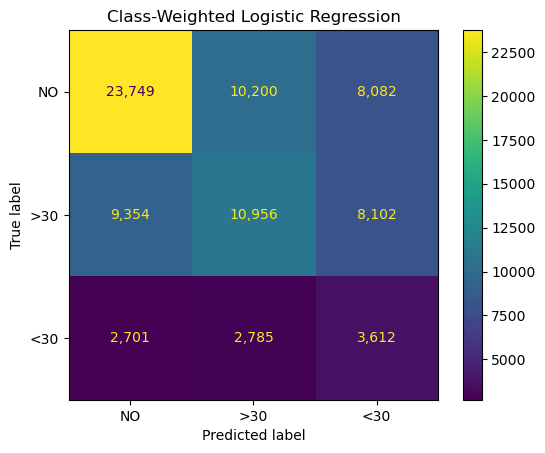

In [181]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_train,
    weighted_oof_predictions,
    labels=["NO", ">30", "<30"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NO", ">30", "<30"]
)

disp.plot(values_format=",d")
plt.title("Class-Weighted Logistic Regression")
plt.show()

In [182]:
print("Original OOF predictions:", logistic_oof_predictions.shape)
print("Weighted OOF predictions:", weighted_oof_predictions.shape)

print("Fitted CV estimators saved:",
      "weighted_scores_with_estimators" in globals())

Original OOF predictions: (79541,)
Weighted OOF predictions: (79541,)
Fitted CV estimators saved: False


In [183]:
print([
    name for name in globals()
    if any(word in name.lower()
           for word in ["proba", "probability", "oof"])
])

['logistic_oof_predictions', 'weighted_oof_predictions']


In [184]:
from sklearn.model_selection import cross_val_predict

weighted_oof_probabilities = cross_val_predict(
    weighted_logistic_model,
    X_train,
    y_train,
    cv=cv_splits,
    method="predict_proba",
    n_jobs=-1
)

print("Probability matrix shape:", weighted_oof_probabilities.shape)
print("Class order:", weighted_logistic_model.classes_)

Probability matrix shape: (79541, 3)


AttributeError: 'LogisticRegression' object has no attribute 'classes_'

In [185]:
print("Probability matrix shape:",
      weighted_oof_probabilities.shape)

print("Class order:",
      weighted_logistic_model.named_steps["classifier"].classes_
      if hasattr(weighted_logistic_model.named_steps["classifier"], "classes_")
      else sorted(y_train.unique()))

Probability matrix shape: (79541, 3)
Class order: ['<30', '>30', 'NO']


In [186]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

classes = np.array(["<30", ">30", "NO"])
early_idx = 0

threshold = 0.20
early_prob = weighted_oof_probabilities[:, early_idx]

# Start with the most likely class
threshold_predictions = classes[
    np.argmax(weighted_oof_probabilities, axis=1)
]

# Give early-readmission class priority above the threshold
threshold_predictions[early_prob >= threshold] = "<30"

print("Confusion matrix:")
print(confusion_matrix(
    y_train,
    threshold_predictions,
    labels=["NO", ">30", "<30"]
))

print("\nClassification report:")
print(classification_report(
    y_train,
    threshold_predictions,
    labels=["NO", ">30", "<30"],
    zero_division=0
))

Confusion matrix:
[[10396  1982 29653]
 [ 3470  1597 23345]
 [  884   330  7884]]

Classification report:
              precision    recall  f1-score   support

          NO       0.70      0.25      0.37     42031
         >30       0.41      0.06      0.10     28412
         <30       0.13      0.87      0.23      9098

    accuracy                           0.25     79541
   macro avg       0.41      0.39      0.23     79541
weighted avg       0.53      0.25      0.25     79541

